# 05 · Análisis supervisado: Clasificación
**Unidad III · Fase CRISP-DM:** 4. Modelado y 5. Evaluación

**Objetivo:** clasificar cada abulón en un **grupo de edad**: Joven (Rings ≤ 8), Adulto (9–10) o Maduro (≥ 11). Criterio documentado en la Unidad I.

🧠 **Clasificación** = predecir una **categoría**. A diferencia de la regresión, aquí no importa el número exacto de anillos, sino la etapa de crecimiento.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
RUTA_PROC = Path("..") / "data" / "processed" / "abalone_limpio.csv"
RUTA_FIG = Path("..") / "docs" / "figuras"
RUTA_MOD = Path("..") / "modelos"
RUTA_FIG.mkdir(parents=True, exist_ok=True)
RUTA_MOD.mkdir(exist_ok=True)

SEMILLA = 42   # fija el azar para que los resultados sean siempre iguales

df = pd.read_csv(RUTA_PROC)
NUMERICAS = ["Length", "Diameter", "Height", "Whole_weight",
             "Shucked_weight", "Viscera_weight", "Shell_weight"]
CATEGORICAS = ["Sex"]
X = df[NUMERICAS + CATEGORICAS]
print("Registros:", len(df))
ORDEN = ["Joven", "Adulto", "Maduro"]
y = df["Grupo_Edad"]
print(y.value_counts().reindex(ORDEN))

Registros: 4169
Grupo_Edad
Joven     1400
Adulto    1322
Maduro    1447
Name: count, dtype: int64


⚠️ **Importante:** `Rings` y `Edad_anios` **no** se usan como predictoras, porque de ellas sale la clase. Sería como dar las respuestas del examen.

## 1. Entrenamiento y prueba
`stratify=y` mantiene la misma proporción de Joven/Adulto/Maduro en ambos conjuntos.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (3335, 8) | Prueba: (834, 8)


In [3]:
# Preprocesamiento:
#  - Sex (texto) -> OneHotEncoder la convierte en 3 columnas de 0/1 (Sex_F, Sex_I, Sex_M)
#  - Medidas numéricas -> StandardScaler las pone en la misma escala (media 0, desviación 1)
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
])

## 2. Modelos a comparar
| Modelo | Idea en una frase |
|---|---|
| **Regresión logística** | Calcula la probabilidad de pertenecer a cada grupo. Simple y explicable. |
| **KNN (k vecinos)** | Mira a los *k* abulones más parecidos y elige el grupo más común entre ellos. |
| **Random Forest** | Muchos árboles votan por un grupo y gana la mayoría. |

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, classification_report,
                             ConfusionMatrixDisplay)

modelos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            random_state=SEMILLA, n_jobs=-1),
}

resultados = []
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    resultados.append({
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_test, pred),
        "Precisión": precision_score(y_test, pred, average="macro"),
        "Recall": recall_score(y_test, pred, average="macro"),
        "F1": f1_score(y_test, pred, average="macro"),
    })

tabla = pd.DataFrame(resultados).round(3)
tabla

,Modelo,Exactitud,Precisión,Recall,F1
0,Regresión logística,0.638,0.645,0.637,0.637
1,KNN (k=15),0.620,0.634,0.620,0.620
2,Random Forest,0.641,0.638,0.639,0.638


## 3. ¿Cómo se leen las métricas?
- **Exactitud (accuracy):** de cada 100 abulones, ¿a cuántos les atinó el grupo?
- **Precisión:** cuando el modelo dice "Maduro", ¿qué tan seguido es verdad?
- **Recall:** de todos los Maduros reales, ¿cuántos encontró?
- **F1:** balance entre precisión y recall.

📌 Como hay 3 clases balanceadas, adivinar al azar daría **≈ 33%** de exactitud.

## 4. Optimización (validación cruzada)

In [5]:
from sklearn.model_selection import GridSearchCV

pipe_rf = Pipeline([("prep", preprocesador),
                    ("modelo", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))])
parametros = {
    "modelo__n_estimators": [100, 200],
    "modelo__min_samples_leaf": [3, 5, 10],
    "modelo__max_features": ["sqrt", 0.5],
}
busqueda = GridSearchCV(pipe_rf, parametros, cv=5, scoring="f1_macro", n_jobs=-1)
busqueda.fit(X_train, y_train)

print("Mejores parámetros:", busqueda.best_params_)
mejor = busqueda.best_estimator_
pred = mejor.predict(X_test)
print(classification_report(y_test, pred, labels=ORDEN, digits=3))

Mejores parámetros: {'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 200}
              precision    recall  f1-score   support

       Joven      0.728     0.775     0.751       280
      Adulto      0.489     0.496     0.492       264
      Maduro      0.698     0.645     0.670       290

    accuracy                          0.641       834
   macro avg      0.638     0.639     0.638       834
weighted avg      0.642     0.641     0.641       834



## 5. Matriz de confusión
Filas = grupo **real**; columnas = grupo **predicho**. La diagonal son los aciertos.

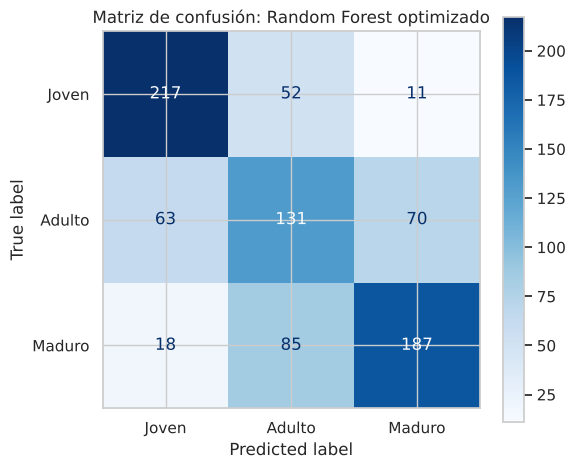

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=ORDEN, cmap="Blues", ax=ax)
ax.set_title("Matriz de confusión: Random Forest optimizado")
plt.tight_layout()
plt.savefig(RUTA_FIG / "10_matriz_confusion.png", dpi=120)
plt.show()

👀 Casi no hay confusión entre **Joven** y **Maduro**: los errores ocurren sobre todo con la clase **Adulto**, que está "en medio". Tiene sentido: un abulón de 8 anillos y otro de 9 son casi iguales físicamente.

## 6. Guardar resultados y modelo

In [7]:
tabla.to_csv(Path("..") / "docs" / "metricas_clasificacion.csv", index=False, encoding="utf-8-sig")
joblib.dump(mejor, RUTA_MOD / "clasificacion_random_forest.joblib", compress=3)
print("Guardado: docs/metricas_clasificacion.csv y modelos/clasificacion_random_forest.joblib")

Guardado: docs/metricas_clasificacion.csv y modelos/clasificacion_random_forest.joblib


## 7. Conclusiones
- Todos los modelos superan con amplitud el 33% de adivinar al azar.
- Joven y Maduro se distinguen bien; la clase **Adulto** es la más difícil por estar entre las otras dos.
- El resultado confirma lo visto en regresión: las medidas físicas permiten estimar la **etapa** de crecimiento de manera razonable, aunque no con precisión perfecta.